<a href="https://colab.research.google.com/github/azkas268-code/liver-tumor-thesis./blob/main/Liver_Tumor_Thesis_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 SETUP: RUN THIS CELL FIRST, EVERY TIME YOU OPEN THE NOTEBOOK

In [25]:
# ========== SETUP: RUN THIS CELL FIRST, EVERY TIME YOU OPEN THE NOTEBOOK ==========
import os
from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

!pip install -q -U monai nibabel SimpleITK pydicom kaggle

# Kaggle key from Drive
import shutil
os.makedirs('/root/.kaggle', exist_ok=True)
shutil.copy('/content/drive/MyDrive/thesis/kaggle.json', '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)

import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "❌ NO GPU (Runtime -> Change runtime type -> T4 GPU)")
print("LiTS data on Colab   :", "✅ yes" if os.path.exists('/content/lits') else "❌ no (run Cell 2.3 + 2.3-part2 when needed)")
print("✅ SETUP DONE")

GPU: Tesla T4
LiTS data on Colab   : ✅ yes
✅ SETUP DONE


In [ ]:
!nvidia-smi

Wed Oct 21 17:35:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

 STEP 1: Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

BASE = '/content/drive/MyDrive/thesis'

folders = [
    'raw/LiTS',          # original LiTS scans
    'raw/IRCADb',        # original 3D-IRCADb scans
    'processed/LiTS',    # cleaned LiTS scans
    'processed/IRCADb',  # cleaned IRCADb scans
    'code',              # your python files
    'checkpoints',       # saved trained models
    'results/csv',       # score tables
    'results/figures',   # pictures for your thesis
]

for f in folders:
    os.makedirs(os.path.join(BASE, f), exist_ok=True)

print("Folders created:")
for f in folders:
    print("  ", os.path.join(BASE, f))

Folders created:
   /content/drive/MyDrive/thesis/raw/LiTS
   /content/drive/MyDrive/thesis/raw/IRCADb
   /content/drive/MyDrive/thesis/processed/LiTS
   /content/drive/MyDrive/thesis/processed/IRCADb
   /content/drive/MyDrive/thesis/code
   /content/drive/MyDrive/thesis/checkpoints
   /content/drive/MyDrive/thesis/results/csv
   /content/drive/MyDrive/thesis/results/figures


In [19]:
!pip install -q monai nibabel SimpleITK pydicom kaggle

In [4]:
import torch, monai, nibabel, SimpleITK, pydicom, cv2, numpy as np
from monai.networks.nets import SegResNet

print("PyTorch version :", torch.__version__)
print("MONAI version   :", monai.__version__)
print("GPU available   :", torch.cuda.is_available())
print("GPU name        :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU")

# Build the same model as the base paper (SegResNet_2335)
model = SegResNet(
    spatial_dims=3,             # 3D model
    in_channels=1,              # 1 input = CT scan
    out_channels=3,             # 3 outputs = background, liver, tumor
    init_filters=8,             # starts with 8 channels (8 -> 16 -> 32 -> 64)
    blocks_down=(2, 3, 3, 5),   # this is the "2335" in the paper's name
    blocks_up=(1, 1, 1),
    norm=("GROUP", {"num_groups": 8}),
    upsample_mode="nontrainable",  # trilinear upsampling, same as the paper
)

params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Model parameters: {params:.2f} million  (paper says about 1.5 million)")

# Test with a fake CT patch
x = torch.zeros(1, 1, 64, 64, 64)
y = model(x)
print("Input shape :", tuple(x.shape))
print("Output shape:", tuple(y.shape), " -> 3 channels = background, liver, tumor")
print("\n✅ STEP 1 COMPLETE!")

PyTorch version : 2.11.0+cu130
MONAI version   : 1.6.1
GPU available   : True
GPU name        : Tesla T4
Model parameters: 1.47 million  (paper says about 1.5 million)
Input shape : (1, 1, 64, 64, 64)
Output shape: (1, 3, 64, 64, 64)  -> 3 channels = background, liver, tumor

✅ STEP 1 COMPLETE!


# STEP 2: Download LiTS dataset

In [5]:
import os, shutil

KAGGLE_IN_DRIVE = '/content/drive/MyDrive/thesis/kaggle.json'
os.makedirs('/root/.kaggle', exist_ok=True)

if os.path.exists(KAGGLE_IN_DRIVE):
    # Second time onwards: take the key from Drive automatically
    shutil.copy(KAGGLE_IN_DRIVE, '/root/.kaggle/kaggle.json')
    print("✅ Found kaggle.json in Drive, no upload needed")
else:
    # First time: upload it from your computer
    from google.colab import files
    print("Please click 'Choose Files' and select your kaggle.json file")
    uploaded = files.upload()
    name = list(uploaded.keys())[0]
    shutil.copy(name, '/root/.kaggle/kaggle.json')
    shutil.copy(name, KAGGLE_IN_DRIVE)   # save a copy in Drive for next time
    print("✅ kaggle.json uploaded and saved to Drive")

os.chmod('/root/.kaggle/kaggle.json', 0o600)   # Kaggle requires the key to be private

✅ Found kaggle.json in Drive, no upload needed


In [6]:
# cell 2.3a

import json

# 1. Check the key file (this does NOT print your secret key)
k = json.load(open('/root/.kaggle/kaggle.json'))
print("Fields in kaggle.json :", list(k.keys()))
print("Kaggle username       :", k.get('username'))

# 2. Update the Kaggle tool to the newest version
!pip install -q -U kaggle
!kaggle --version

# 3. Test: ask Kaggle to list the dataset files (no download yet)
print("\n=== Testing connection to Kaggle ===")
!kaggle datasets files andrewmvd/liver-tumor-segmentation | head -8

Fields in kaggle.json : ['username', 'key']
Kaggle username       : azkasaiff
Kaggle CLI 2.2.5

=== Testing connection to Kaggle ===
Next Page Token = CfDJ8FwkkMkekkBCtzoFDl4Vj7jAXkYq6Q1FFr7Z_Z5jDlqlUq1TzFHofH48HEo8v9P1igqyqUpAaxuXXmdSrjtOFI798IcZBJH4gzv7vmUxRHa0UwtX5ZfxJ3y5LM8yNjeriFdDb8qGDNtt4X2v3l6BwaeJRocXh3vXTA
name                                     size  creationDate                
----------------------------------  ---------  --------------------------  
segmentations/segmentation-0.nii     39321952  2020-07-11 22:00:49.268000  
segmentations/segmentation-1.nii     32244064  2020-07-11 22:00:48.913000  
segmentations/segmentation-10.nii   131334496  2020-07-11 22:00:56.984000  
segmentations/segmentation-100.nii  179568992  2020-07-11 22:02:10.855000  
segmentations/segmentation-101.nii  358089056  2020-07-11 22:02:06.060000  


In [7]:
# Cell 2.3: Download + unzip (all in one)
# ===== STEP 2.3: Download + unzip LiTS in one go =====


import os, shutil, glob, zipfile

# 1. Make sure Drive is connected
from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# 2. Install / update tools (Colab forgets them after a restart)
!pip install -q -U kaggle nibabel

# 3. Copy the Kaggle key from Drive
os.makedirs('/root/.kaggle', exist_ok=True)
shutil.copy('/content/drive/MyDrive/thesis/kaggle.json', '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)
print("✅ Kaggle key ready")

# 4. Download (about 1-2 minutes)
os.makedirs('/content/lits', exist_ok=True)
!kaggle datasets download -d andrewmvd/liver-tumor-segmentation -p /content/lits

# 5. Unzip with a space check, then delete the zip
for z in glob.glob('/content/lits/*.zip'):
    zf = zipfile.ZipFile(z)
    need_gb = sum(i.file_size for i in zf.infolist()) / 1e9
    free_gb = shutil.disk_usage('/content').free / 1e9
    print(f"\nSpace needed to unzip : {need_gb:.1f} GB")
    print(f"Free space available  : {free_gb:.1f} GB")
    if need_gb < free_gb - 3:
        print("Unzipping... (5-10 minutes, please wait)")
        zf.extractall('/content/lits')
        zf.close()
        os.remove(z)
        print("✅ Unzip finished, zip file deleted")
    else:
        print("❌ NOT enough space! Send me a screenshot.")

# 6. Show the result
print("\n=== Folders inside /content/lits ===")
!ls /content/lits
!du -sh /content/lits
!df -h /content | tail -1


✅ Kaggle key ready
Dataset URL: https://www.kaggle.com/datasets/andrewmvd/liver-tumor-segmentation
License(s): Attribution-NonCommercial-NoDerivatives 4.0 International (CC BY-NC-ND 4.0)
100% 4.84G/4.84G [00:35<00:00, 147MB/s]


Space needed to unzip : 30.9 GB
Free space available  : 70.1 GB
Unzipping... (5-10 minutes, please wait)
✅ Unzip finished, zip file deleted

=== Folders inside /content/lits ===
segmentations  volume_pt1  volume_pt2  volume_pt3  volume_pt4  volume_pt5
29G	/content/lits
overlay         113G   72G   42G  64% /


In [8]:
# Cell 2.3-part2: Downloading the missing scans


# ===== STEP 2.3 (part 2): Download CT scans 51-130 =====
import os, shutil, glob, zipfile

# 1. Check that part 2 exists on Kaggle (lists a few files)
print("=== Files in part 2 ===")
!kaggle datasets files andrewmvd/liver-tumor-segmentation-part-2 | head -6

# 2. Download part 2 into the SAME folder
!kaggle datasets download -d andrewmvd/liver-tumor-segmentation-part-2 -p /content/lits

# 3. Unzip with a space check, then delete the zip
for z in glob.glob('/content/lits/*.zip'):
    zf = zipfile.ZipFile(z)
    need_gb = sum(i.file_size for i in zf.infolist()) / 1e9
    free_gb = shutil.disk_usage('/content').free / 1e9
    print(f"\nSpace needed to unzip : {need_gb:.1f} GB")
    print(f"Free space available  : {free_gb:.1f} GB")
    if need_gb < free_gb - 3:
        print("Unzipping... (5-10 minutes, please wait)")
        zf.extractall('/content/lits')
        zf.close()
        os.remove(z)
        print("✅ Unzip finished, zip file deleted")
    else:
        print("❌ NOT enough space! Send me a screenshot.")

# 4. Show the result
print("\n=== Folders inside /content/lits ===")
!ls /content/lits
!du -sh /content/lits
!df -h /content | tail -1

=== Files in part 2 ===
Next Page Token = CfDJ8FwkkMkekkBCtzoFDl4Vj7hu7WHPVPzwuA8oIMGEfG6N0z0GeYIqZqRxopwgZnUUTnhHHmFDYJVNtK3tB5O70iFrBMRLRJATx2hcc1rJfCwg79zKLRDK6sWn0_rfJ0uxHS09jiQ6DyhdZinKrZr_
name                            size  creationDate                
-------------------------  ---------  --------------------------  
volume_pt6/volume-100.nii  359137632  2020-07-11 22:17:54.331000  
volume_pt6/volume-51.nii   119014032  2020-07-11 22:17:49.482000  
volume_pt6/volume-52.nii   124256944  2020-07-11 22:17:50.852000  
Dataset URL: https://www.kaggle.com/datasets/andrewmvd/liver-tumor-segmentation-part-2
License(s): Attribution-NonCommercial-NoDerivatives 4.0 International (CC BY-NC-ND 4.0)
100% 10.8G/10.8G [01:28<00:00, 131MB/s]


Space needed to unzip : 22.7 GB
Free space available  : 32.7 GB
Unzipping... (5-10 minutes, please wait)
✅ Unzip finished, zip file deleted

=== Folders inside /content/lits ===
segmentations  volume_pt2  volume_pt4  volume_pt6
volume_pt1     volume_pt3

In [9]:
# Cell 2.4: Check all 131 scans

import glob, re

vols = glob.glob('/content/lits/**/volume-*.nii*', recursive=True)
segs = glob.glob('/content/lits/**/segmentation-*.nii*', recursive=True)

def case_id(path):
    # takes "volume-12.nii" and returns 12
    return int(re.findall(r'-(\d+)\.nii', path)[0])

vol_map = {case_id(p): p for p in vols}
seg_map = {case_id(p): p for p in segs}
ids = sorted(set(vol_map) & set(seg_map))

print("CT scans found :", len(vol_map))
print("Masks found    :", len(seg_map))
print("Complete pairs :", len(ids))

if len(ids) == 0:
    print("\n❌ No scans found! Please send me a screenshot.")
else:
    print("Case IDs from", ids[0], "to", ids[-1])
    missing = set(range(131)) - set(ids)
    print("Missing cases  :", missing if missing else "None ✅")

CT scans found : 131
Masks found    : 131
Complete pairs : 131
Case IDs from 0 to 130
Missing cases  : None ✅


In [10]:
# checking datasets was erased or not:


import os
if os.path.exists('/content/lits'):
    print("✅ Data is still here. Just run Cell 2.4 again, then Cell 2.5.")
    !du -sh /content/lits
else:
    print("❌ Data was erased (Colab restarted).")
    print("   Run: Step 1 Cell 2 (mount Drive) -> Cell 2.3 -> Cell 2.3-part2 -> Cell 2.4 -> Cell 2.5")

✅ Data is still here. Just run Cell 2.4 again, then Cell 2.5.
50G	/content/lits


In [11]:
# Cell 2.5: Look inside one scan

import nibabel as nib
import numpy as np

img = nib.load(vol_map[0])
seg = nib.load(seg_map[0])

ct   = np.asanyarray(img.dataobj)
mask = np.asanyarray(seg.dataobj).astype(np.uint8)

print("Scan shape (X, Y, slices):", ct.shape)
print("Voxel spacing (mm)       :", tuple(round(float(s), 3) for s in img.header.get_zooms()))
print("HU values from", ct.min(), "to", ct.max())
print("Labels in mask           :", np.unique(mask))
print("Liver voxels :", int((mask == 1).sum()))
print("Tumor voxels :", int((mask == 2).sum()))
print(f"Tumor is only {100 * (mask == 2).sum() / mask.size:.3f}% of the whole scan!")


Scan shape (X, Y, slices): (512, 512, 75)
Voxel spacing (mm)       : (0.703, 0.703, 5.0)
HU values from -3024.0 to 1410.0
Labels in mask           : [0 1 2]
Liver voxels : 550036
Tumor voxels : 2591
Tumor is only 0.013% of the whole scan!


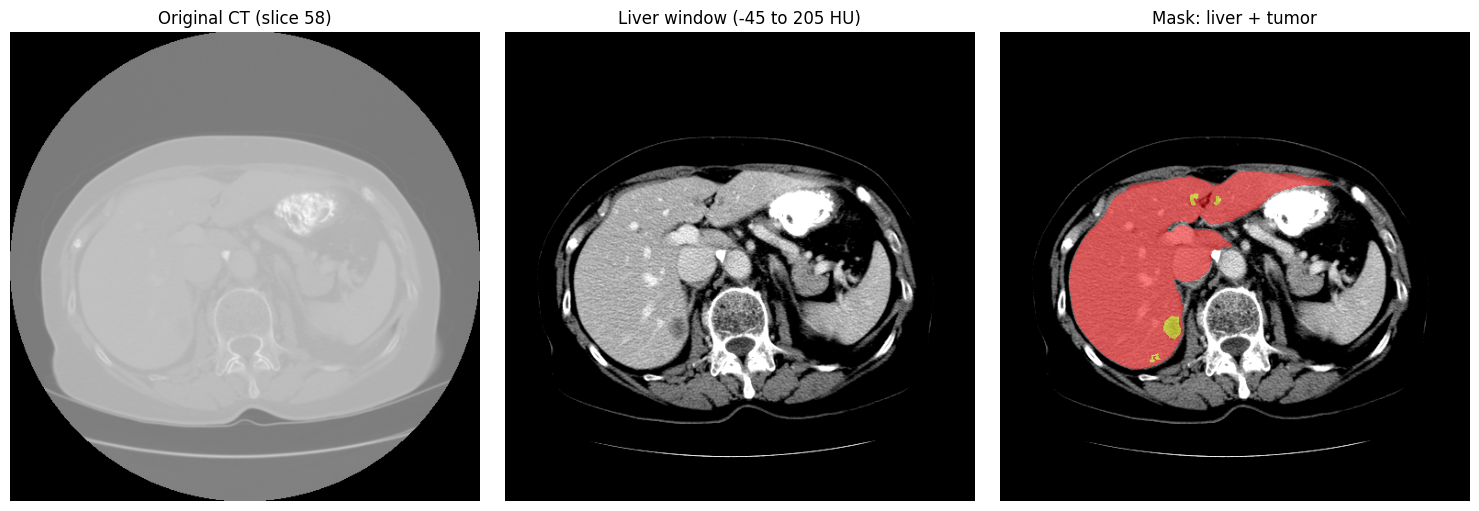

In [12]:
# cell 2.6 see the scan

import matplotlib.pyplot as plt

# find the slice with the most tumor
tumor_per_slice = (mask == 2).sum(axis=(0, 1))
if tumor_per_slice.max() > 0:
    z = int(np.argmax(tumor_per_slice))
else:
    z = int(np.argmax((mask == 1).sum(axis=(0, 1))))

ct_slice   = np.rot90(ct[:, :, z])
mask_slice = np.rot90(mask[:, :, z])
ct_window  = np.clip(ct_slice, -45, 205)   # the paper's liver window (WL 80, WW 250)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(ct_slice, cmap='gray');  ax[0].set_title(f'Original CT (slice {z})')
ax[1].imshow(ct_window, cmap='gray'); ax[1].set_title('Liver window (-45 to 205 HU)')
ax[2].imshow(ct_window, cmap='gray')
ax[2].imshow(np.ma.masked_where(mask_slice == 0, mask_slice), cmap='autumn', alpha=0.5)
ax[2].set_title('Mask: liver + tumor')
for a in ax: a.axis('off')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/thesis/results/figures/step2_case0.png', dpi=150)
plt.show()

Number of different scan sizes: 118

Most common sizes:
shape
(512, 512, 836)    3
(512, 512, 751)    3
(512, 512, 122)    2
(512, 512, 244)    2
(512, 512, 841)    2
Name: count, dtype: int64

Group A (same size (512, 512, 836)): [92, 113, 117]
Group B (different sizes)         : [18, 29, 32, 36, 102]


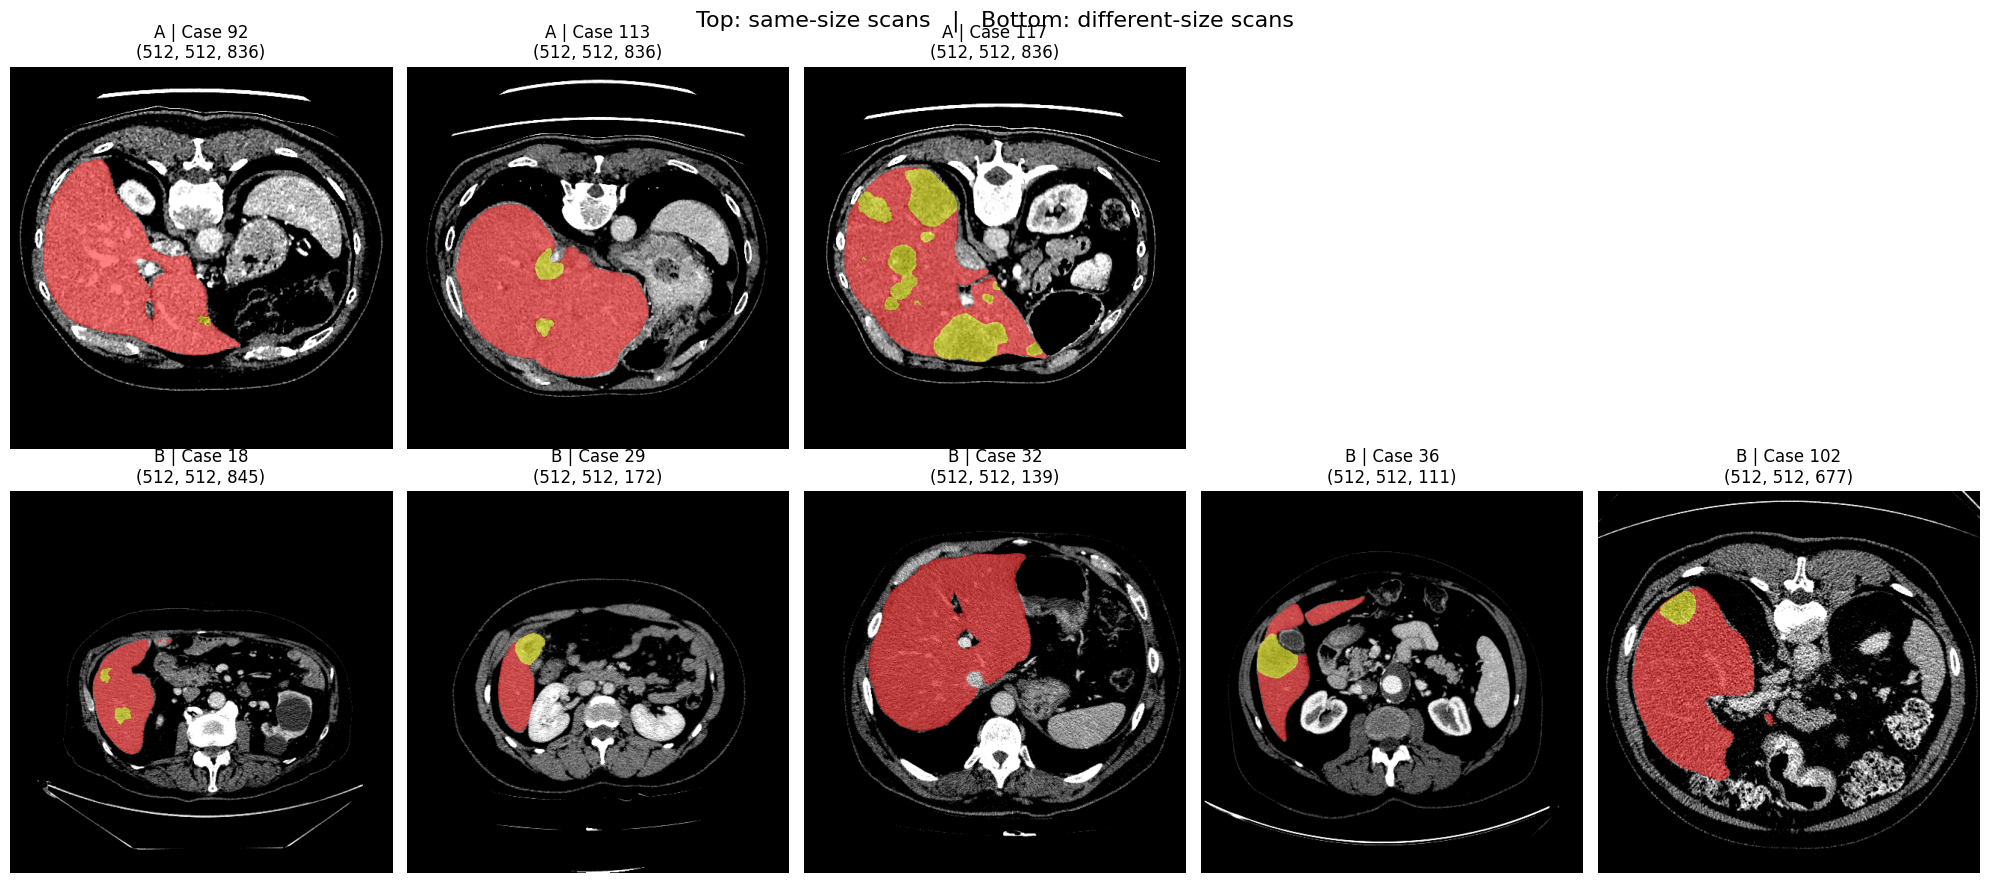

            group  case           shape  slice_thickness_mm  liver_%  tumor_%  has_tumor
     A: same size    92 (512, 512, 836)                 0.8    1.539    0.001       True
     A: same size   113 (512, 512, 836)                 0.8    1.499    0.038       True
     A: same size   117 (512, 512, 836)                 0.8    1.830    0.472       True
B: different size    18 (512, 512, 845)                 0.8    0.872    0.005       True
B: different size    29 (512, 512, 172)                 1.0    3.624    0.031       True
B: different size    32 (512, 512, 139)                 1.0    5.830    0.000      False
B: different size    36 (512, 512, 111)                 1.0    4.213    0.136       True
B: different size   102 (512, 512, 677)                 0.7    2.852    0.027       True


In [14]:
# Cell 2.7: Compare same-size scans vs different-size scans
import random
import pandas as pd
import matplotlib.pyplot as plt

# 1. Read only the size info of every scan (fast, no full loading)
info = []
for i in ids:
    img = nib.load(vol_map[i])
    info.append({'case': i,
                 'shape': img.shape,
                 'slice_thickness_mm': round(float(img.header.get_zooms()[2]), 2)})
info = pd.DataFrame(info)

print("Number of different scan sizes:", info['shape'].nunique())
print("\nMost common sizes:")
print(info['shape'].value_counts().head(5))

random.seed(42)   # same result every time

# 2. GROUP A: 5 random scans with the SAME size (most common size)
common_shape = info['shape'].value_counts().index[0]
same_cases = list(info[info['shape'] == common_shape]['case'])
group_a = sorted(random.sample(same_cases, min(5, len(same_cases))))

# 3. GROUP B: 5 random scans that all have DIFFERENT sizes
#    (one scan from each of 5 randomly chosen sizes, not the common size)
other = info[info['shape'] != common_shape]
shapes = random.sample(list(other['shape'].unique()), 5)
group_b = sorted(random.choice(list(other[other['shape'] == s]['case'])) for s in shapes)

print(f"\nGroup A (same size {common_shape}):", group_a)
print("Group B (different sizes)         :", group_b)

# 4. Statistics + pictures
rows = []
fig, ax = plt.subplots(2, 5, figsize=(20, 9))

for r, (group_name, group) in enumerate([('A: same size', group_a), ('B: different size', group_b)]):
    for k, i in enumerate(group):
        img = nib.load(vol_map[i])
        ct = np.asanyarray(img.dataobj)
        m  = np.asanyarray(nib.load(seg_map[i]).dataobj).astype(np.uint8)

        rows.append({
            'group': group_name,
            'case': i,
            'shape': ct.shape,
            'slice_thickness_mm': round(float(img.header.get_zooms()[2]), 2),
            'liver_%': round(100 * (m == 1).sum() / m.size, 3),
            'tumor_%': round(100 * (m == 2).sum() / m.size, 3),
            'has_tumor': bool((m == 2).any()),
        })

        t = (m == 2).sum(axis=(0, 1))
        z = int(np.argmax(t)) if t.max() > 0 else int(np.argmax((m == 1).sum(axis=(0, 1))))
        ct_w = np.clip(np.rot90(ct[:, :, z]), -45, 205)
        ms   = np.rot90(m[:, :, z])
        a = ax[r, k]
        a.imshow(ct_w, cmap='gray')
        a.imshow(np.ma.masked_where(ms == 0, ms), cmap='autumn', alpha=0.5)
        a.set_title(f'{group_name[0]} | Case {i}\n{ct.shape}')
        a.axis('off')

  # hide empty boxes if a group has fewer than 5 scans
for r, group in enumerate([group_a, group_b]):
    for k in range(len(group), 5):
        ax[r, k].axis('off')

plt.suptitle('Top: same-size scans   |   Bottom: different-size scans', fontsize=16)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/thesis/results/figures/step2_same_vs_different.png', dpi=150)
plt.show()

df = pd.DataFrame(rows)
df.to_csv('/content/drive/MyDrive/thesis/results/csv/lits_same_vs_different.csv', index=False)
print(df.to_string(index=False))

**STEP 3: Download the 3D-IRCADb-01 dataset**

In [22]:

# cell 3.1:  Download IRCADb from Kaggle

import os, shutil
from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# Kaggle key from Drive (same as in Step 2)
!pip install -q -U kaggle
os.makedirs('/root/.kaggle', exist_ok=True)
shutil.copy('/content/drive/MyDrive/thesis/kaggle.json', '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)

# Download and unzip
!kaggle datasets download -d sarahelqersh/3dircadb1 -p /content/ircad --unzip

# Show what we got
print("\n=== Size ===")
!du -sh /content/ircad
print("\n=== What is inside (first 40 lines) ===")
!find /content/ircad -maxdepth 3 | head -40

Dataset URL: https://www.kaggle.com/datasets/sarahelqersh/3dircadb1
License(s): unknown
100% 786M/786M [00:11<00:00, 73.4MB/s]


=== Size ===
10G	/content/ircad

=== What is inside (first 40 lines) ===
/content/ircad
/content/ircad/3Dircadb1
/content/ircad/3Dircadb1/3Dircadb1.11
/content/ircad/3Dircadb1/3Dircadb1.11/PATIENT_DICOM
/content/ircad/3Dircadb1/3Dircadb1.11/MASKS_DICOM
/content/ircad/3Dircadb1/3Dircadb1.11/LICENSE.txt
/content/ircad/3Dircadb1/3Dircadb1.11/liver_11.jpg
/content/ircad/3Dircadb1/3Dircadb1.11/LABELLED_DICOM
/content/ircad/3Dircadb1/3Dircadb1.11/MESHES_VTK
/content/ircad/3Dircadb1/3Dircadb1.14
/content/ircad/3Dircadb1/3Dircadb1.14/PATIENT_DICOM
/content/ircad/3Dircadb1/3Dircadb1.14/liver_14.jpg
/content/ircad/3Dircadb1/3Dircadb1.14/MASKS_DICOM
/content/ircad/3Dircadb1/3Dircadb1.14/LICENSE.txt
/content/ircad/3Dircadb1/3Dircadb1.14/LABELLED_DICOM
/content/ircad/3Dircadb1/3Dircadb1.14/MESHES_VTK
/content/ircad/3Dircadb1/3Dircadb1.9
/content/ircad/3Dircadb1/3Dircadb1.

Cell 3.2 : Unzip everything and find the 20 patients

In [23]:


import glob, zipfile, re, os

# 1. If there is still a big zip inside, open it
for z in glob.glob('/content/ircad/**/*.zip', recursive=True):
    if 'DICOM' not in os.path.basename(z) and 'VTK' not in os.path.basename(z):
        print("Opening:", z)
        zipfile.ZipFile(z).extractall(os.path.dirname(z))

# 2. Find the 20 patient folders (3Dircadb1.1 ... 3Dircadb1.20)
found = {}
for d in glob.glob('/content/ircad/**/3Dircadb1.*', recursive=True):
    m = re.search(r'3Dircadb1\.(\d+)$', d)
    if os.path.isdir(d) and m and int(m.group(1)) not in found:
        found[int(m.group(1))] = d
patient_dirs = [found[k] for k in sorted(found)]
print("Patient folders found:", len(patient_dirs), "(should be 20)")

# 3. Unzip PATIENT_DICOM and MASKS_DICOM inside each patient (if still zipped)
for p in patient_dirs:
    for name in ['PATIENT_DICOM', 'MASKS_DICOM']:
        folder, z = os.path.join(p, name), os.path.join(p, name + '.zip')
        if not os.path.isdir(folder) and os.path.exists(z):
            zipfile.ZipFile(z).extractall(p)
print("✅ CT images and masks are ready")

# 4. Show the mask folders of each patient
for p in patient_dirs:
    masks = sorted(os.listdir(os.path.join(p, 'MASKS_DICOM')))
    tumor_masks = [m for m in masks if 'tumor' in m.lower()]
    print(f"{os.path.basename(p):14s} -> liver: {'liver' in masks} | tumor folders: {tumor_masks}")

Patient folders found: 20 (should be 20)
✅ CT images and masks are ready
3Dircadb1.1    -> liver: False | tumor folders: []
3Dircadb1.2    -> liver: False | tumor folders: []
3Dircadb1.3    -> liver: False | tumor folders: []
3Dircadb1.4    -> liver: False | tumor folders: []
3Dircadb1.5    -> liver: False | tumor folders: []
3Dircadb1.6    -> liver: False | tumor folders: []
3Dircadb1.7    -> liver: False | tumor folders: []
3Dircadb1.8    -> liver: False | tumor folders: []
3Dircadb1.9    -> liver: False | tumor folders: []
3Dircadb1.10   -> liver: False | tumor folders: []
3Dircadb1.11   -> liver: False | tumor folders: []
3Dircadb1.12   -> liver: False | tumor folders: []
3Dircadb1.13   -> liver: False | tumor folders: []
3Dircadb1.14   -> liver: False | tumor folders: []
3Dircadb1.15   -> liver: False | tumor folders: []
3Dircadb1.16   -> liver: False | tumor folders: []
3Dircadb1.17   -> liver: False | tumor folders: []
3Dircadb1.18   -> liver: False | tumor folders: []
3Dircadb1

Cell 3.2b: Look inside one patient folder

In [29]:

import os
p = patient_dirs[0]
print("Patient folder:", p)
print("Inside it     :", sorted(os.listdir(p)))

n = 0
for root, dirs, files in os.walk(os.path.join(p, 'PATIENT_DICOM')):
    if files:
        print(f"\nFolder: {root}\n  {len(files)} files, e.g. {sorted(files)[:5]}")
        print("  size of first file:", os.path.getsize(os.path.join(root, sorted(files)[0])), "bytes")
    n += len(files)
print("\nTotal CT slice files found:", n)

Patient folder: /content/ircad/3Dircadb1/3Dircadb1.1
Inside it     : ['LABELLED_DICOM', 'LICENSE.txt', 'MASKS_DICOM', 'MESHES_VTK', 'PATIENT_DICOM', 'liver_01.jpg']

Folder: /content/ircad/3Dircadb1/3Dircadb1.1/PATIENT_DICOM/PATIENT_DICOM
  129 files, e.g. ['image_0', 'image_1', 'image_10', 'image_100', 'image_101']
  size of first file: 525428 bytes

Total CT slice files found: 129


CELL 3.3: Convert 3D-IRCADb to NIfTI (LiTS format)

In [34]:
import SimpleITK as sitk
import numpy as np
import csv, re, os

OUT = '/content/drive/MyDrive/thesis/raw/IRCADb'
os.makedirs(OUT, exist_ok=True)

def dicom_files(folder):
    """Find all slice files in a folder (also inside sub-folders) -> {file name: full path}"""
    found = {}
    for root, _, files in os.walk(folder):
        for f in files:
            if f.startswith('.') or f.lower().endswith(('.txt', '.zip', '.jpg', '.png', '.vtk')):
                continue
            found[f] = os.path.join(root, f)
    return found

def slice_number(name):
    """'image_12' -> 12, so slices are sorted 0, 1, 2, ... (not 0, 1, 10, 11, ...)"""
    nums = re.findall(r'\d+', name)
    return int(nums[-1]) if nums else 0

def read_series(paths):
    r = sitk.ImageSeriesReader()
    r.SetFileNames(paths)
    return r.Execute()

def find_mask_root(p):
    """Go down into MASKS_DICOM (or MASKS_DICOM/MASKS_DICOM) until we find the folder that contains 'liver'"""
    for root, dirs, _ in os.walk(os.path.join(p, 'MASKS_DICOM')):
        if 'liver' in [d.lower() for d in dirs]:
            return root
    return None

info = []
for p in patient_dirs:
    pid = int(p.split('.')[-1])

    # --- CT: all slice files, sorted by number ---
    ct_dict = dicom_files(os.path.join(p, 'PATIENT_DICOM'))
    names = sorted(ct_dict, key=slice_number)
    if not names:
        print(f"❌ Patient {pid}: no CT files found, skipped"); continue
    ct = read_series([ct_dict[n] for n in names])
    ct_arr = sitk.GetArrayFromImage(ct)

    # --- masks: same file names, same order as the CT ---
    mask_root = find_mask_root(p)
    if mask_root is None:
        print(f"❌ Patient {pid}: no liver mask folder found, skipped"); continue
    def read_mask(folder):
        md = dicom_files(folder)
        return sitk.GetArrayFromImage(read_series([md[n] for n in names])) > 0

    label = np.zeros(ct_arr.shape, dtype=np.uint8)
    liver_folder = [m for m in os.listdir(mask_root) if m.lower() == 'liver'][0]
    label[read_mask(os.path.join(mask_root, liver_folder))] = 1            # liver = 1
    tumor_folders = [m for m in os.listdir(mask_root) if 'livertumor' in m.lower()]   # only LIVER tumors (skip adrenal/other-organ tumors)
    for t in tumor_folders:
        label[read_mask(os.path.join(mask_root, t))] = 2                   # tumor = 2

    # --- save ---
    lab_img = sitk.GetImageFromArray(label)
    lab_img.CopyInformation(ct)
    sitk.WriteImage(sitk.Cast(ct, sitk.sitkInt16), f'{OUT}/volume-{pid}.nii.gz')
    sitk.WriteImage(lab_img, f'{OUT}/segmentation-{pid}.nii.gz')

    row = dict(patient=pid, slices=ct_arr.shape[0], spacing=tuple(round(s, 3) for s in ct.GetSpacing()),
               liver_voxels=int((label == 1).sum()), tumor_voxels=int((label == 2).sum()),
               tumor_folders=len(tumor_folders))
    info.append(row)
    print(f"✅ Patient {pid:2d} | slices {row['slices']} | spacing {row['spacing']} | "
          f"tumor folders {len(tumor_folders)} | tumor voxels {row['tumor_voxels']}")

with open('/content/drive/MyDrive/thesis/results/csv/ircadb_info.csv', 'w', newline='') as f:
    w = csv.DictWriter(f, fieldnames=info[0].keys()); w.writeheader(); w.writerows(info)

print(f"\n✅ Saved {len(info)} patients to Drive: {OUT}")
print("Patients WITH tumor:", sum(r['tumor_voxels'] > 0 for r in info), "of", len(info))

✅ Patient  1 | slices 129 | spacing (0.57, 0.57, 1.6) | tumor folders 7 | tumor voxels 214268
✅ Patient  2 | slices 172 | spacing (0.782, 0.782, 1.6) | tumor folders 1 | tumor voxels 14062
✅ Patient  3 | slices 200 | spacing (0.625, 0.625, 1.25) | tumor folders 1 | tumor voxels 14252
✅ Patient  4 | slices 91 | spacing (0.742, 0.742, 2.0) | tumor folders 1 | tumor voxels 6736
✅ Patient  5 | slices 139 | spacing (0.782, 0.782, 1.6) | tumor folders 0 | tumor voxels 0
✅ Patient  6 | slices 135 | spacing (0.782, 0.782, 1.6) | tumor folders 1 | tumor voxels 434721
✅ Patient  7 | slices 151 | spacing (0.782, 0.782, 1.6) | tumor folders 0 | tumor voxels 0
✅ Patient  8 | slices 124 | spacing (0.561, 0.561, 1.6) | tumor folders 3 | tumor voxels 20318
✅ Patient  9 | slices 111 | spacing (0.873, 0.873, 2.0) | tumor folders 1 | tumor voxels 39484
✅ Patient 10 | slices 122 | spacing (0.736, 0.736, 1.6) | tumor folders 1 | tumor voxels 14981
✅ Patient 11 | slices 132 | spacing (0.72, 0.72, 1.6) | tum

 cell 3.3b: Show the names of the tumor mask folders of each patient (to check they are LIVER tumors)

In [31]:
# Show the names of the tumor mask folders of each patient (to check they are LIVER tumors)
for p in patient_dirs:
    root = find_mask_root(p)
    tumors = sorted(m for m in os.listdir(root) if 'tumor' in m.lower())
    print(f"Patient {int(p.split('.')[-1]):2d}: {tumors}")

Patient  1: ['livertumor01', 'livertumor02', 'livertumor03', 'livertumor04', 'livertumor05', 'livertumor06', 'livertumor07']
Patient  2: ['livertumor']
Patient  3: ['livertumor']
Patient  4: ['livertumor']
Patient  5: ['leftsurretumor', 'rightsurretumor']
Patient  6: ['livertumor']
Patient  7: ['tumor']
Patient  8: ['livertumor01', 'livertumor02', 'livertumor03']
Patient  9: ['livertumor']
Patient 10: ['livertumor']
Patient 11: []
Patient 12: ['livertumor']
Patient 13: ['livertumor']
Patient 14: []
Patient 15: ['livertumor']
Patient 16: ['livertumor']
Patient 17: ['livertumor1', 'livertumor2']
Patient 18: ['livertumor']
Patient 19: ['livertumors']
Patient 20: []


Cell 3.3c: Check where each tumor is (inside the liver or not)

In [32]:
# Check what % of each tumor mask lies inside the liver (to decide if it is a LIVER tumor)
from scipy import ndimage

for p in patient_dirs:
    pid = int(p.split('.')[-1])
    ct_dict = dicom_files(os.path.join(p, 'PATIENT_DICOM'))
    names = sorted(ct_dict, key=slice_number)
    root = find_mask_root(p)

    def read_mask(folder):
        md = dicom_files(folder)
        return sitk.GetArrayFromImage(read_series([md[n] for n in names])) > 0

    tumor_folders = sorted(m for m in os.listdir(root) if 'tumor' in m.lower())
    if not tumor_folders:
        continue
    liver = read_mask(os.path.join(root, 'liver'))
    liver_area = ndimage.binary_dilation(ndimage.binary_fill_holes(liver), iterations=3)  # liver + small border
    for t in tumor_folders:
        tm = read_mask(os.path.join(root, t))
        inside = 100 * (tm & liver_area).sum() / max(tm.sum(), 1)
        print(f"Patient {pid:2d} | {t:16s} | {inside:5.1f}% inside the liver")

Patient  1 | livertumor01     | 100.0% inside the liver
Patient  1 | livertumor02     | 100.0% inside the liver
Patient  1 | livertumor03     | 100.0% inside the liver
Patient  1 | livertumor04     | 100.0% inside the liver
Patient  1 | livertumor05     | 100.0% inside the liver
Patient  1 | livertumor06     | 100.0% inside the liver
Patient  1 | livertumor07     | 100.0% inside the liver
Patient  2 | livertumor       | 100.0% inside the liver
Patient  3 | livertumor       | 100.0% inside the liver
Patient  4 | livertumor       | 100.0% inside the liver
Patient  5 | leftsurretumor   |   0.0% inside the liver
Patient  5 | rightsurretumor  |  13.8% inside the liver
Patient  6 | livertumor       | 100.0% inside the liver
Patient  7 | tumor            |   3.2% inside the liver
Patient  8 | livertumor01     | 100.0% inside the liver
Patient  8 | livertumor02     | 100.0% inside the liver
Patient  8 | livertumor03     | 100.0% inside the liver
Patient  9 | livertumor       | 100.0% inside th

cell 3.4 Looking at one IRCADb scan